**Docente:** MSc. Juan Carlos Gonzalez

# Segmentación de clientes: caso Depratti

**Deber 7: PCA y DBSCAN**

**Nombre Estudiante:** 

Se trabajará con un dataset **sintético** de 600 clientes inspirado en el contexto comercial de Deprati (Ecuador). Los registros no corresponden a clientes reales.

**Ruta de trabajo:** objetivo empresarial → selección de variables → correlaciones → estandarización → PCA → K-Means → interpretación comercial.


## 1. Objetivo empresarial

El equipo de Marketing necesita identificar tipos de clientes según sus hábitos de compra. La empresa podría utilizar los grupos para proponer promociones o acciones de fidelización distintas.



### Descripción de las columnas del dataset

Cada fila representa a un cliente de la tienda y cada columna describe un aspecto de ese cliente.

| Columna | Significado para el negocio | Unidad |
| --- | --- | --- |
| `cliente_id` | Código que identifica a cada cliente. No describe su comportamiento de compra. | Código |
| `ciudad` | Ciudad del cliente. Permite analizar después cómo se distribuyen los grupos. | Texto |
| `edad` | Edad del cliente. Aporta información sobre su perfil demográfico. | Años |
| `antiguedad_meses` | Tiempo que lleva como cliente. Distingue a los clientes nuevos de los consolidados. | Meses |
| `compras_12m` | Número de compras del último año. Mide la frecuencia con la que compra. | Compras |
| `gasto_anual_usd` | Dinero gastado durante el año. Refleja el valor económico del cliente para la tienda. | USD |
| `ticket_promedio_usd` | Gasto promedio por compra. Muestra si realiza compras de valor alto o bajo. | USD |
| `descuento_promedio_pct` | Descuento promedio de sus compras. Ayuda a identificar su sensibilidad a las promociones. | % |
| `porcentaje_compras_online` | Proporción de compras en línea. Indica su preferencia por el canal digital. | % |
| `porcentaje_moda` | Parte de sus compras que corresponde a la categoría moda. | % |
| `porcentaje_hogar` | Parte de sus compras que corresponde a la categoría hogar. | % |
| `porcentaje_tecnologia` | Parte de sus compras que corresponde a la categoría tecnología. | % |
| `porcentaje_belleza` | Parte de sus compras que corresponde a la categoría belleza. | % |
| `devoluciones_12m` | Número de devoluciones del último año. Puede señalar insatisfacción y genera costos operativos. | Devoluciones |
| `visitas_web_mes` | Visitas mensuales al sitio web. Refleja su interés e interacción digital. | Visitas |
| `dias_desde_ultima_compra` | Días de inactividad. Un valor alto puede indicar riesgo de que deje de comprar. | Días |

**Relaciones observadas en las primeras filas del dataset:** el ticket promedio equivale al gasto anual dividido para el número de compras, y los cuatro porcentajes por categoría suman 100 %.

## 2. Cargar el dataset

El archivo `deprati_clientes_sinteticos_600.csv` debe estar en la misma carpeta que este notebook.

In [1]:
# Librerías para manejar la tabla de datos (pandas) y para graficar (matplotlib, seaborn).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Herramientas de scikit-learn para el flujo de la práctica:
# StandardScaler (misma escala) -> PCA (menos dimensiones) -> KMeans (grupos).
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Carga el dataset. Cada fila es un cliente y cada columna una característica.
df = pd.read_csv('deprati_clientes_sinteticos_600.csv')


print(df.shape)

(600, 16)


## 3. Seleccionar 8 características

No seleccionamos las primeras ocho columnas por su posición. Elegimos variables que tienen relación con el objetivo de Marketing(para hacer esto bien, hay que entender el negocio):

| Característica              | ¿Qué representa?                  |
| --------------------------- | --------------------------------- |
| `gasto_anual_usd`           | Dinero gastado durante el año     |
| `compras_12m`               | Número de compras del último año  |
| `ticket_promedio_usd`       | Gasto promedio por compra         |
| `descuento_promedio_pct`    | Descuento promedio de sus compras |
| `porcentaje_compras_online` | Proporción de compras en línea    |
| `devoluciones_12m`          | Número de devoluciones            |
| `visitas_web_mes`           | Visitas mensuales al sitio web    |
| `dias_desde_ultima_compra`  | Días de inactividad               |

Se excluyen cliente_id y ciudad: no describen el comportamiento de compra. Otras columnas podrían elegirse en un análisis diferente.

**Observación:** gasto anual, número de compras y ticket promedio están relacionados; veremos esa relación en la matriz de correlaciones.


In [2]:
columnas = [
    'gasto_anual_usd',
    'compras_12m',
    'ticket_promedio_usd',
    'descuento_promedio_pct',
    'porcentaje_compras_online',
    'devoluciones_12m',
    'visitas_web_mes',
    'dias_desde_ultima_compra'
]

# X sera la matriz de trabajo: conservar todas las filas y solo las 8 columnas seleccionadas
X = df[columnas]
# Se espera(600, 8): 600 observaciones y 8 dimenciones
print(X.shape)
X.head()

(600, 8)


,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra
0,1289.43,9,143.27,24.2,13.0,0,12,2
1,1619.64,11,147.24,8.4,15.8,1,11,50
2,1247.00,5,249.40,7.0,17.1,0,5,102
3,67.84,1,67.84,28.5,15.5,0,6,112
4,959.68,4,239.92,2.9,62.2,0,16,4


Antes de continuar, revisamos si existen datos faltantes y observamos estadísticas básicas.


In [3]:
# Contar los valores faltantes por columna
#PCA y KMEANS no acpetan valores nulos
print(X.isnull().sum())
#Sacar estadisticas basicas, medias y desviaciones
X.describe().round(2)

gasto_anual_usd              0
compras_12m                  0
ticket_promedio_usd          0
descuento_promedio_pct       0
porcentaje_compras_online    0
devoluciones_12m             0
visitas_web_mes              0
dias_desde_ultima_compra     0
dtype: int64


,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,836.40,4.38,189.14,14.98,34.62,0.28,10.71,66.12
std,640.09,2.81,104.13,9.83,26.83,0.55,6.26,74.53
min,36.58,1.00,36.58,0.00,0.00,0.00,0.00,1.00
25%,252.75,2.00,99.20,7.30,12.28,0.00,6.00,14.00
50%,785.63,4.00,172.86,13.00,28.15,0.00,10.00,38.00
75%,1220.62,6.00,261.80,21.82,54.85,0.00,16.00,94.00
max,3235.84,14.00,479.61,40.70,100.00,4.00,27.00,360.00


## 4. Analizar correlaciones

La correlación ayuda a observar si dos características tienden a aumentar o disminuir juntas. Sus valores van de -1 a 1:

- Cercano a **1**: relación positiva fuerte.
- Cercano a **-1**: relación negativa fuerte.
- Cercano a **0**: relación lineal débil.

Las correlaciones permiten revisar que variables comparten información antes de resumirlas con componentes en PCA


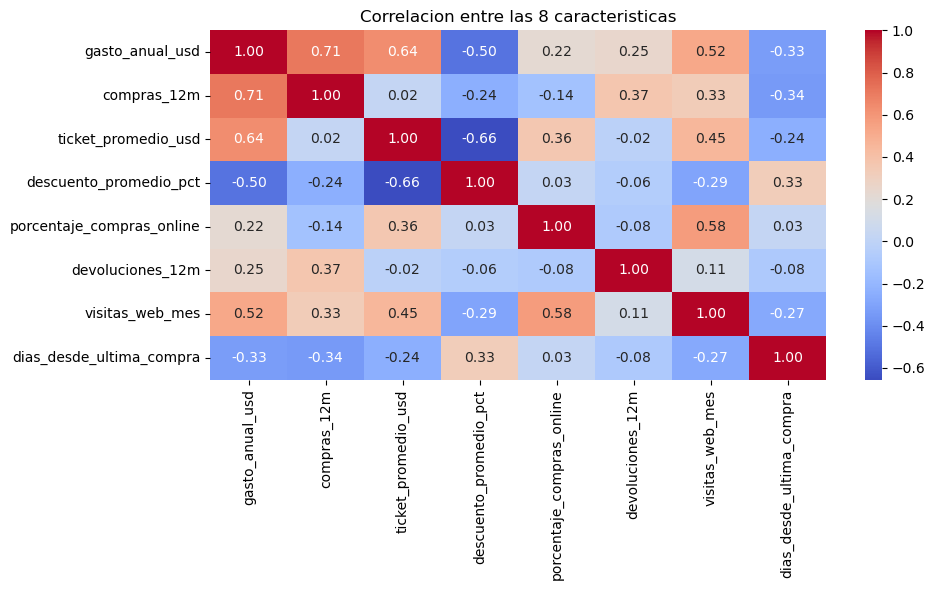

In [4]:
plt.figure(figsize=(10,6))
# X.corr() calcula la correlacion entre cada par de variables (1 a -1)
#annot = True escribe el valor en cada celda

sns.heatmap(X.corr(), annot = True, fmt = '.2f', cmap= 'coolwarm')
plt.title("Correlacion entre las 8 caracteristicas")
plt.tight_layout()
plt.show()

**¿Cuáles son las dos variables con mayor correlación positiva? ¿Tendría sentido que estén relacionadas en una tienda?**


## 5. Estandarizar las características

Las variables tienen unidades diferentes: dólares, porcentajes, visitas y días. Si usamos directamente esos valores, las variables con números más grandes podrían dominar el cálculo de distancias.

`StandardScaler` transforma cada característica para que tenga aproximadamente media 0 y desviación estándar 1.


In [5]:
#Kmeans usa distancia euclidiana y PCA prioriza las direcciones con mas varianza
escalador = StandardScaler()
#fit calcular la media y la desviacion estandar de cada columna
#transform aplizar z = (valor-media)/ desviacion on estado dejo media en 0 y desviacion 1
#El resultado es unarreglo de Numpy, ya no un dataset
X_escalado = escalador.fit_transform(X)

#Comparar 3 clientes y columnas antes y despues de escalar
print("Antes de estandarizar:")
print(X.iloc[:3,:3])

print("Despues de estandarizar:")
print(X_escalado[:3,:3].round(2))
#Es decir ese cliente gasta 1.22 desviaciones por encima del promedio y compra
#2.35 desviaciones por encima del promedio

Antes de estandarizar:
   gasto_anual_usd  compras_12m  ticket_promedio_usd
0          1289.43            9               143.27
1          1619.64           11               147.24
2          1247.00            5               249.40
Despues de estandarizar:
[[ 0.71  1.65 -0.44]
 [ 1.22  2.36 -0.4 ]
 [ 0.64  0.22  0.58]]


Cada valor individual puede ser mayor que 1 o menor que -1, lo que se cumple es que al promediar toda la columna da aproximadamente 0 y su dispersión da 1, porque se utilizo StandarScaler

## 6. Aplicar PCA: de 8 características a 2 componentes

En esta práctica configuramos PCA para generar **dos componentes nuevos**, aunque podría generar hasta ocho. Estos componentes combinan la información de las ocho características; PCA no se limita a escoger dos columnas del dataset.

Primero calcularemos los dos componentes y luego verificaremos qué porcentaje de la varianza total representan. **Con dos componentes se explica el 59.44 % de la varianza total** (CP1: 39.48 % y CP2: 19.96 %).


In [6]:
#n_component = 2 conservar solo los primeros componentes principales
#CP1 capturar la mayor variabilidad posible, CP2 la mayor variabilidad restante
pca = PCA(n_components=2)
#fit encontrar las direcciones de esos componentes y transform los proyecta a cada cliente
X_pca = pca.fit_transform(X_escalado)

#PCA cambias las columnas, no elimina las filas de clientes
#se pasa de (600, 8) a (600, 2)
print('Forma inicial: ', X_escalado.shape)
print('Forma despues de PCA: ', X_pca.shape)


Forma inicial:  (600, 8)
Forma despues de PCA:  (600, 2)


Varianza explciada CP1:  39.48 %
Varianza explciada CP2:  19.96 %
Varianza explciada total:  59.44 %


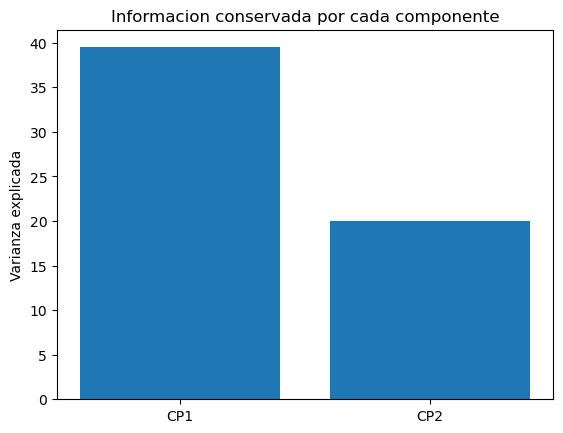

In [7]:
#expalined_variance_ratio de la proporcion de variables que explica cada componente
varianza = pca.explained_variance_ratio_*100

print('Varianza explciada CP1: ', round(varianza[0],2), '%')
print('Varianza explciada CP2: ', round(varianza[1],2), '%')
print('Varianza explciada total: ', round(varianza.sum(),2), '%')

#Grafico de barras PCA
plt.bar(['CP1', 'CP2'], varianza)
plt.ylabel("Varianza explicada")
plt.title('Informacion conservada por cada componente')
plt.show()

In [8]:
pca_completo = PCA() 
pca_completo.fit(X_escalado) 
varianza_8 = pca_completo.explained_variance_ratio_ * 100 

tabla_varianza = pd.DataFrame({ 
    'Componente': [f'CP{i}' for i in range(1, 9)], 
    'Varianza explicada (%)': varianza_8.round(2), 
    'Varianza acumulada (%)': varianza_8.cumsum().round(2) 
})

tabla_varianza

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,CP1,39.48,39.48
1,CP2,19.96,59.44
2,CP3,14.29,73.73
3,CP4,10.16,83.89
4,CP5,8.11,92.00
5,CP6,4.68,96.68
6,CP7,2.83,99.51
7,CP8,0.49,100.00


**Importante:** usar solo dos componentes facilita el gráfico, pero puede perder información. Si la varianza explicada total es baja, los grupos obtenidos podrían ser diferentes de los que se encontrarían usando más componentes.


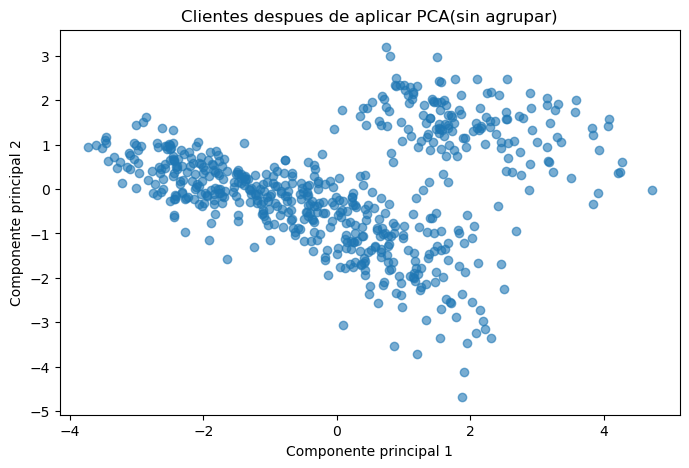

In [9]:
#Cada punto es un cliente representado con sus dos componentes, todavia no existen grupos
plt.figure(figsize=(8,5))
#toma todas las filas de CP1 y el segundo elige, todas las de CP2
#ALPHA DA transparencia para distinguir puntos que esten sobrepuestos
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=0.6)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clientes despues de aplicar PCA(sin agrupar)")
plt.show()

#No hay umbral o regla para determinar la cantidad de componentes
#Lo ideal sera siempre tener la mayor cantidad de representacion 

## 7. Librerías adicionales para DBSCAN

In [10]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score

## 8. ¿Qué es DBSCAN?
**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) forma grupos por **densidad**: un grupo es una zona donde los puntos están muy juntos, separada de otras zonas por espacios casi vacíos.

Tiene **2 hiperparámetros**:

| Parámetro | Significado |
| --- | --- |
| `eps` (ε) | Radio del vecindario: qué tan cerca debe estar un punto para considerarse vecino. |
| `min_samples` | Mínimo de puntos (contándose a sí mismo) dentro del radio `eps` para que una zona sea "densa". |

Cada punto termina en uno de tres tipos:
- **Punto núcleo:** tiene al menos `min_samples` puntos dentro de `eps`.
- **Punto frontera:** no es núcleo, pero está dentro del radio de un núcleo.
- **Ruido (etiqueta -1):** no es ni núcleo ni frontera → cliente atípico.

**Diferencias clave con K-Means**

| | K-Means | DBSCAN |
| --- | --- | --- |
| ¿Hay que fijar el número de grupos? | Sí (`k`) | **No**, sale de los datos |
| Forma de los grupos | Esféricos / convexos | **Cualquier forma** |
| Valores atípicos | Los obliga a pertenecer a un grupo | Los marca como **ruido** (-1) |
| Tamaño de grupos | Tiende a equilibrados | Pueden ser muy desiguales |
| Parámetros delicados | `k` | `eps` y `min_samples` |

## 9. Elegir `eps` con el gráfico de k-distancias
Regla práctica: `min_samples` ≥ (dimensiones + 1); con ~600 puntos y 2 dimensiones es razonable probar entre 4 y 10. Aquí usamos **`min_samples = 10`**.

Para cada cliente se calcula la distancia a su vecino número 10 (él mismo cuenta como el primero, igual que en DBSCAN). Se ordenan de menor a mayor: el **"codo"** de la curva sugiere el `eps`: antes del codo los puntos están en zonas densas; después, en zonas dispersas (ruido).

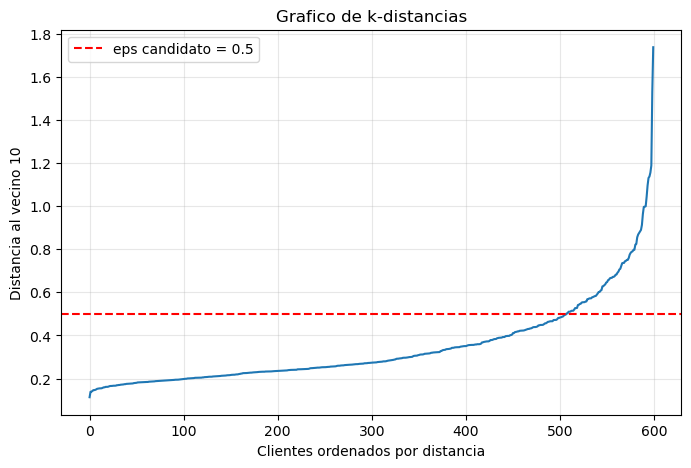

Percentiles de la distancia: [0.27 0.45 0.59 0.74]


In [11]:
min_samples = 10

vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distancias, _ = vecinos.kneighbors(X_pca)
k_dist = np.sort(distancias[:, -1])          # distancia al vecino 10, ordenada

plt.figure(figsize=(8,5))
plt.plot(k_dist)
plt.axhline(0.5, color='red', linestyle='--', label='eps candidato = 0.5')
plt.xlabel('Clientes ordenados por distancia')
plt.ylabel(f'Distancia al vecino {min_samples}')
plt.title('Grafico de k-distancias')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('Percentiles de la distancia:', np.percentile(k_dist, [50, 80, 90, 95]).round(2))

**Lectura:** la curva sube suavemente hasta ~0.5–0.6 y luego se dispara. Tomamos **eps ≈ 0.5** como candidato; en la sección 10 lo validamos probando valores vecinos.

## 10. Probar combinaciones de `eps` y `min_samples`
DBSCAN es muy sensible a sus parámetros. Probamos una cuadrícula y miramos cuántos grupos salen, cuánto ruido hay y el índice de silueta (calculado sin los puntos de ruido).

In [12]:
filas = []
for ms in [4, 5, 8, 10]:
    for eps in [0.3, 0.4, 0.5, 0.6, 0.7]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
        n_grupos = len(set(lab)) - (1 if -1 in lab else 0)
        ruido = int((lab == -1).sum())
        sil = silhouette_score(X_pca[lab != -1], lab[lab != -1]) if n_grupos >= 2 else np.nan
        filas.append({'min_samples': ms, 'eps': eps, 'grupos': n_grupos,
                      'ruido': ruido, '% ruido': round(ruido/len(lab)*100, 1),
                      'silueta': round(sil, 3) if not np.isnan(sil) else np.nan})

tabla = pd.DataFrame(filas)
tabla

,min_samples,eps,grupos,ruido,% ruido,silueta
0,4,0.3,7,57,9.5,0.094
1,4,0.4,4,23,3.8,0.339
2,4,0.5,2,15,2.5,0.350
3,4,0.6,1,7,1.2,NaN
4,4,0.7,1,3,0.5,NaN
5,5,0.3,7,76,12.7,0.156
6,5,0.4,4,33,5.5,0.376
7,5,0.5,1,18,3.0,NaN
8,5,0.6,1,7,1.2,NaN
9,5,0.7,1,3,0.5,NaN


**Lectura:**
- `eps` muy pequeño → demasiado ruido y grupos diminutos.
- `eps` muy grande (≥ 0.7) → todo se funde en **un solo grupo**.
- `min_samples=10, eps=0.5` da **2 grupos**, ~6 % de ruido y buena silueta: es un punto de equilibrio. Es el modelo final.

## 11. Modelo final DBSCAN

In [13]:
dbscan = DBSCAN(eps=0.5, min_samples=10)
etiquetas = dbscan.fit_predict(X_pca)            # -1 = ruido

n_grupos = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
n_ruido = (etiquetas == -1).sum()
print('Grupos encontrados:', n_grupos)
print('Clientes ruido    :', n_ruido, f'({n_ruido/len(etiquetas)*100:.1f} %)')
print()
print(pd.Series(etiquetas).value_counts().sort_index())

# Tipos de punto: nucleo, frontera, ruido
es_nucleo = np.zeros(len(etiquetas), dtype=bool)
es_nucleo[dbscan.core_sample_indices_] = True
print('\nPuntos nucleo   :', es_nucleo.sum())
print('Puntos frontera :', ((~es_nucleo) & (etiquetas != -1)).sum())
print('Puntos ruido    :', n_ruido)

Grupos encontrados: 2
Clientes ruido    : 36 (6.0 %)

-1     36
 0    434
 1    130
Name: count, dtype: int64

Puntos nucleo   : 507
Puntos frontera : 57
Puntos ruido    : 36


## 12. Visualizar los grupos y el ruido

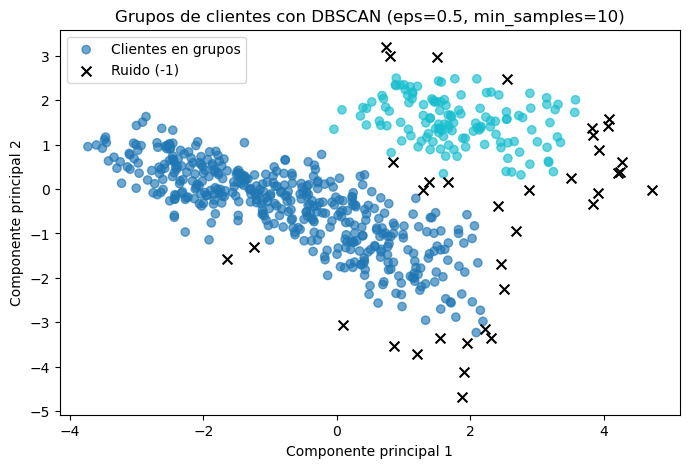

In [14]:
plt.figure(figsize=(8,5))
mascara = etiquetas != -1
plt.scatter(X_pca[mascara,0], X_pca[mascara,1], c=etiquetas[mascara], cmap='tab10', alpha=0.65, label='Clientes en grupos')
plt.scatter(X_pca[~mascara,0], X_pca[~mascara,1], c='black', marker='x', s=50, label='Ruido (-1)')
plt.xlabel('Componente principal 1'); plt.ylabel('Componente principal 2')
plt.title('Grupos de clientes con DBSCAN (eps=0.5, min_samples=10)')
plt.legend(); plt.show()

## 13. Interpretación comercial
Volvemos a las variables **originales** (USD, días, %) y promediamos por grupo. El grupo **-1** son los clientes que DBSCAN considera atípicos.

In [15]:
resultado = df.copy()
resultado['dbscan'] = etiquetas

resumen_db = resultado.groupby('dbscan')[columnas].mean().round(1)
resumen_db['n_clientes'] = resultado.groupby('dbscan').size()
resumen_db

,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra,n_clientes
dbscan,,,,,,,,,
-1,1740.9,6.8,281.5,9.3,47.8,1.1,15.1,34.7,36
0,638.5,4.3,145.1,17.2,22.4,0.3,8.0,74.2,434
1,1246.7,4.0,310.5,9.3,71.9,0.2,18.4,47.8,130


In [16]:
# Nombres comerciales (segun los promedios de arriba)
# -1 = Clientes atipicos / VIP de alto gasto y mas devoluciones
#  0 = Cliente tradicional/mixto: gasto medio-bajo, poco online, mas descuento
#  1 = Cliente digital premium: compra online (~72 %), ticket alto (~$310), muchas visitas web

**Lectura:**
- **Grupo 1 (130 clientes):** compradores digitales de ticket alto y pocas devoluciones y poco descuento. Ideal para campañas online y lanzamientos premium.
- **Grupo 0 (434 clientes):** el grueso de la base; gasto menor, más sensibles al descuento, menos digitales y más días sin comprar. Sirve para promociones y reactivación.
- **Ruido (36 clientes):** gastan mucho (~$1 741), compran más veces (6.8) y devuelven más (1.1). No son "errores": son los clientes extremos que K-Means mezcla con otros grupos. Merecen un trato personalizado.

## 14. Re-ejecutar K-Means (k = 4) para comparar
Mismo PCA, mismos datos, mismos parámetros que el taller.

In [17]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
grupos_km = kmeans.fit_predict(X_pca)
resultado['kmeans'] = grupos_km

print(pd.Series(grupos_km).value_counts().sort_index())
resumen_km = resultado.groupby('kmeans')[columnas].mean().round(1)
resumen_km['n_clientes'] = resultado.groupby('kmeans').size()
resumen_km

0    150
1    160
2    130
3    160
Name: count, dtype: int64


c:\Users\merce\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra,n_clientes
kmeans,,,,,,,,,
0,1355.5,4.2,320.3,8.8,71.2,0.2,18.4,47.8,150
1,654.4,3.6,196.6,11.6,14.0,0.1,6.7,53.4,160
2,1293.7,8.4,158.8,12.1,16.2,0.8,12.4,24.1,130
3,160.2,2.1,83.4,26.5,35.9,0.1,6.2,130.2,160


## 15. Comparación DBSCAN vs K-Means

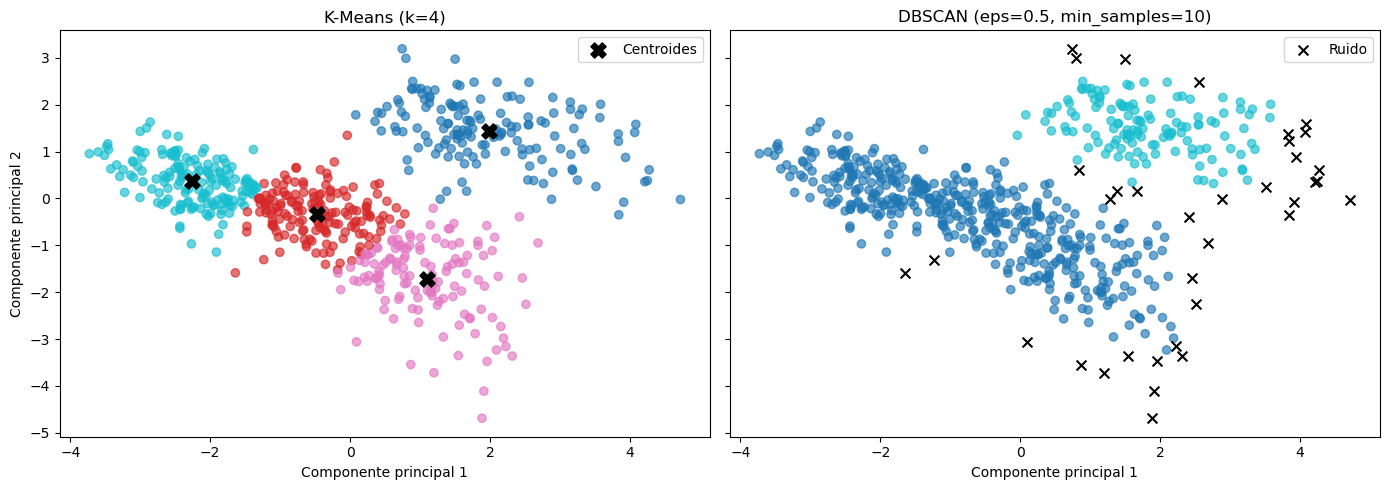

In [18]:
fig, ejes = plt.subplots(1, 2, figsize=(14,5), sharex=True, sharey=True)

ejes[0].scatter(X_pca[:,0], X_pca[:,1], c=grupos_km, cmap='tab10', alpha=0.65)
ejes[0].scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
                c='black', marker='X', s=120, label='Centroides')
ejes[0].set_title('K-Means (k=4)'); ejes[0].legend()

ejes[1].scatter(X_pca[mascara,0], X_pca[mascara,1], c=etiquetas[mascara], cmap='tab10', alpha=0.65)
ejes[1].scatter(X_pca[~mascara,0], X_pca[~mascara,1], c='black', marker='x', s=50, label='Ruido')
ejes[1].set_title('DBSCAN (eps=0.5, min_samples=10)'); ejes[1].legend()

for e in ejes:
    e.set_xlabel('Componente principal 1')
ejes[0].set_ylabel('Componente principal 2')
plt.tight_layout(); plt.show()

DBSCAN   -1    0    1
K-Means              
0        21    0  129
1         2  157    1
2        13  117    0
3         0  160    0


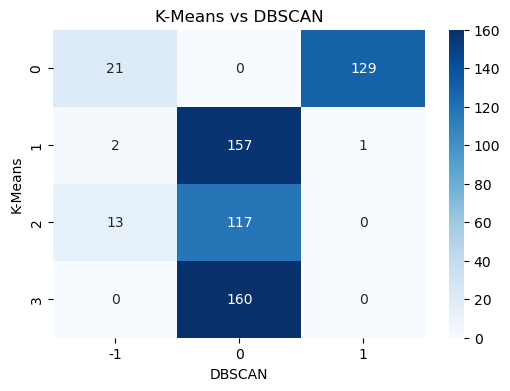

In [19]:
# Tabla cruzada: como se reparte cada grupo de K-Means entre los grupos de DBSCAN
cruce = pd.crosstab(resultado['kmeans'], resultado['dbscan'],
                    rownames=['K-Means'], colnames=['DBSCAN'])
print(cruce)

plt.figure(figsize=(6,4))
sns.heatmap(cruce, annot=True, fmt='d', cmap='Blues')
plt.title('K-Means vs DBSCAN')
plt.show()

In [20]:
# Metricas (para DBSCAN se excluye el ruido; para ser justos se muestra tambien K-Means sin esos mismos puntos)
sil_km        = silhouette_score(X_pca, grupos_km)
sil_km_sinr   = silhouette_score(X_pca[mascara], grupos_km[mascara])
sil_db        = silhouette_score(X_pca[mascara], etiquetas[mascara])
dbi_km        = davies_bouldin_score(X_pca, grupos_km)
dbi_db        = davies_bouldin_score(X_pca[mascara], etiquetas[mascara])
ari           = adjusted_rand_score(grupos_km[mascara], etiquetas[mascara])

comparacion = pd.DataFrame({
    'K-Means (k=4)': [4, 0, round(sil_km,3), round(dbi_km,3)],
    'DBSCAN': [n_grupos, n_ruido, round(sil_db,3), round(dbi_db,3)]
}, index=['Grupos', 'Clientes ruido', 'Silueta (mayor es mejor)', 'Davies-Bouldin (menor es mejor)'])
display(comparacion)
print('Silueta de K-Means sin los puntos ruido de DBSCAN:', round(sil_km_sinr, 3))
print('Indice Rand ajustado (acuerdo entre ambos):', round(ari, 3))

,K-Means (k=4),DBSCAN
Grupos,4.000,2.000
Clientes ruido,0.000,36.000
Silueta (mayor es mejor),0.469,0.476
Davies-Bouldin (menor es mejor),0.692,0.734


Silueta de K-Means sin los puntos ruido de DBSCAN: 0.493
Indice Rand ajustado (acuerdo entre ambos): 0.311


## 16. Conclusiones
1. **Número de grupos:** K-Means obliga a elegir `k` (4); DBSCAN lo decide solo y encuentra **2 zonas densas + ruido**.
2. **Lo que coinciden:** ambos aíslan al grupo **digital premium** (K-Means 0 ≈ DBSCAN 1: 129 de 150 clientes coinciden).
3. **Lo que difiere:** DBSCAN **fusiona** los otros tres grupos de K-Means (1, 2 y 3) en uno solo, porque en el plano PCA no hay un hueco vacío entre ellos: la nube es continua. K-Means los separa por distancia a centroides, pero esa separación es más una "partición" que una frontera natural.
4. **Valores atípicos:** DBSCAN aísla **36 clientes** (6 %) con gasto y devoluciones altos; K-Means los reparte dentro de sus grupos y distorsionan los promedios.
5. **Para el negocio:** K-Means es más útil para segmentar y diseñar **4 acciones comerciales** distintas; DBSCAN es más útil para **detectar el grupo claramente distinto y los clientes atípicos**. Se pueden usar juntos.
6. **Limitaciones:** PCA con 2 componentes conserva solo 59.44 % de la varianza; DBSCAN es sensible a `eps` y `min_samples`; con densidades parecidas entre grupos no separa bien.

**Docente:** MSc. Juan Carlos Gonzalez